# LAB: Vision-Language Models, CLIP & LLaVA

bf16 · `.venv` (torch cu128)

## Exercise 1: Installation and model loading

In [1]:
# Cell 1.1: environment check (nothing is installed here; the venv already has everything)
import torch, transformers, PIL

print("torch       ", torch.__version__)
print("transformers", transformers.__version__)
print("CUDA ok     ", torch.cuda.is_available())
print("GPU         ", torch.cuda.get_device_name(0))
print("capability  ", torch.cuda.get_device_capability(0))
print("bf16 ok     ", torch.cuda.is_bf16_supported())

device = "cuda"
dtype  = torch.bfloat16

torch        2.11.0+cu128
transformers 5.20.1
CUDA ok      True
GPU          NVIDIA GeForce RTX 5090
capability   (12, 0)
bf16 ok      True


In [2]:
from transformers import CLIPModel, CLIPProcessor
#What it does:
#- CLIPModel is the neural network that turns images and text into vectors.
#- CLIPProcessor prepares the inputs: it resizes the image and turns the text into tokens.
#- .to(device) puts the model on the GPU, and .eval() switches it to inference mode. 

MODEL_ID = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(MODEL_ID, dtype=dtype).to(device).eval()
processor = CLIPProcessor.from_pretrained(MODEL_ID)
print("loaded")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

loaded


In [3]:
print("vision tower:", sum(p.numel() for p in model.vision_model.parameters()) // 10**6, "M params")
print("text tower:  ", sum(p.numel() for p in model.text_model.parameters()) // 10**6, "M params")
print("image → shared space:", model.visual_projection)
print("text  → shared space:", model.text_projection)

vision tower: 87 M params
text tower:   63 M params
image → shared space: Linear(in_features=768, out_features=512, bias=False)
text  → shared space: Linear(in_features=512, out_features=512, bias=False)


### Exercise 1 — Answers

**Q1. What is CLIP?**
CLIP (Contrastive Language-Image Pre-Training) takes an image and several sentences as input and gives a score for each sentence.
It was trained on 400 million image–caption pairs so that matching images and texts end up close in a shared space.
The score is relative: it only ranks the sentences you give it.

**Q2. What are its two main components?**
- The **image tower**: it outputs 768 numbers, and a projection maps them to a 512-d vector.
- The **text tower**: it turns each sentence into a 512-d vector.

Both live in the same 512-d space, so they can be compared.

**Q3. What is the role of `CLIPProcessor`?**
It prepares the inputs: it resizes the image and turns the text into tokens.
It returns tensors: `pixel_values` [1, 3, 224, 224] for the image and `input_ids` for the text.

**Q4. What is the role of `CLIPModel`?**
It encodes the image and the texts into embeddings and computes their scaled cosine similarities (the logits, `logits_per_image`).
The softmax that turns them into probabilities is applied afterwards.

## Exercise 2: Load an image

size: (640, 480)
mode: RGB


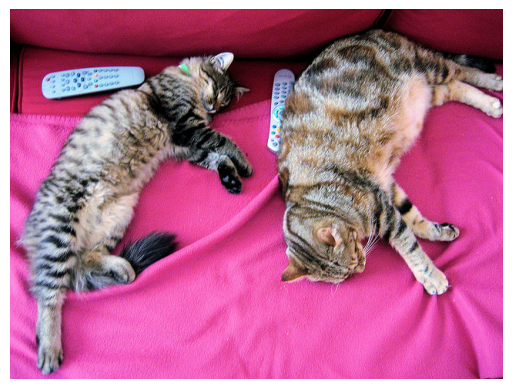

In [4]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open("image.jpg").convert("RGB")
print("size:", image.size)
print("mode:", image.mode)

plt.imshow(image); plt.axis("off");

In [5]:
import numpy as np

arr = np.array(image)
print("numpy shape:", arr.shape)
print("dtype:      ", arr.dtype)
print("min / max:  ", arr.min(), arr.max())
print("top-left pixel (R,G,B):", arr[0, 0])

numpy shape: (480, 640, 3)
dtype:       uint8
min / max:   0 255
top-left pixel (R,G,B): [140  25  56]


### Exercise 2 — Answers

 **Q5. What is the size of the image?**
 The size is (640, 480): 640 pixels wide × 480 pixels high.
 As a NumPy array, the shape is (480, 640, 3): height × width × channels.

 **Q6. What type of data is stored in the PIL image object?**
 RGB pixels: each pixel has 3 values (Red, Green, Blue), stored as `uint8` integers from 0 to 255.

## Exercise 3: Image/Text similarity

In [6]:
texts = ["a photo of a cat", "a photo of a dog", "a photo of a car","a photo of a horse", "a photo of a person"]

print(texts)

['a photo of a cat', 'a photo of a dog', 'a photo of a car', 'a photo of a horse', 'a photo of a person']


In [7]:
inputs = processor(text=texts, images=image, return_tensors="pt", padding=True).to(device)

print("pixel_values:", tuple(inputs["pixel_values"].shape))
print("input_ids:   ", tuple(inputs["input_ids"].shape))

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0]

for text, p in zip(texts, probs):
    print(f"{text:22s} {p.item():.4f}")

pixel_values: (1, 3, 224, 224)
input_ids:    (5, 7)


a photo of a cat       0.9805
a photo of a dog       0.0052
a photo of a car       0.0022
a photo of a horse     0.0019
a photo of a person    0.0085


In [8]:
img_emb = outputs.image_embeds          # [1, 512], already normalised
txt_emb = outputs.text_embeds           # [5, 512]
print("norm of image vector:", img_emb.norm().item())

cos = (img_emb @ txt_emb.T)[0]          # raw cosine similarities
scale = model.logit_scale.exp().item()  # the learned ×100
logits = scale * cos
by_hand = torch.exp(logits) / torch.exp(logits).sum()   # softmax, written out

print("scale:", round(scale, 2))
for t, c, l, p in zip(texts, cos, logits, by_hand):
    print(f"{t:22s} cos={c.item():.3f}  ×scale={l.item():6.2f}  softmax={p.item():.4f}")

norm of image vector: 1.0
scale: 99.0
a photo of a cat       cos=0.246  ×scale= 24.38  softmax=0.9805
a photo of a dog       cos=0.193  ×scale= 19.12  softmax=0.0051
a photo of a car       cos=0.185  ×scale= 18.25  softmax=0.0021
a photo of a horse     cos=0.184  ×scale= 18.12  softmax=0.0019
a photo of a person    cos=0.198  ×scale= 19.62  softmax=0.0084


### Exercise 3 — Answers

**Q7.** "a photo of a cat", with probability **0.9805**.

**Q8.** Yes, the image shows two cats. CLIP doesn't count them; it only says the whole image is cat-like.

**Q9.** CLIP was trained on 400M image–caption pairs. Its two towers map images and sentences into the
**same 512-d shared space**, and training pulled matching pairs (a cat image and "a cat") close together
and pushed non-matching pairs apart. So the cosine (the angle) between an image vector and a sentence
vector measures how well they match.

**Q10.** Softmax turns the logits into a probability distribution that sums to 1: exp(x) / sum(exp).
The raw cosines were close (0.246 vs 0.198), but the ×99 scale makes the softmax very sharp,
so 98% does not mean CLIP is 98% sure.

## Exercise 4: Zero-shot classification

In [9]:
# Exercise 4 — zero-shot classification
def classify_image(image, classes, template="a photo of a {}"):
    texts = [template.format(c) for c in classes]            # "cat" → "a photo of a cat"
    inputs = processor(text=texts, images=image, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        probs = model(**inputs).logits_per_image.softmax(dim=1)[0]   # [num_classes]
    best = probs.argmax().item()
    return classes[best], probs[best].item()

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]
prediction, probability = classify_image(image, classes)
print("Prediction:", prediction, f"({probability:.4f})")

# Q13 experiment: what if the correct class is NOT in the list?
pred2, prob2 = classify_image(image, ["dog", "car", "airplane", "horse", "bird"])
print("Without 'cat':", pred2, f"({prob2:.4f})")

Prediction: cat (0.9883)
Without 'cat': dog (0.4414)


### Exercise 4 — Answers

**Q11. What is zero-shot classification?**
Classifying an image into classes the model was never explicitly trained on. We only give the class *names*:
each class becomes a sentence ("a photo of a cat"), and CLIP picks the sentence closest to the image.

**Q12. Why is it not necessary to train a new classifier?**
CLIP already learned a shared image–text space from 400M image–caption pairs. The text encoder turns any class
name into a vector, so the "classifier weights" are just the text embeddings of the class prompts. Changing the
classes means changing a list of words; no labelled images and no training are needed.

**Q13. What happens if the correct class is not included in the candidate classes?**
CLIP still picks one of the given classes, because softmax always distributes 100% over the list we supply.
Experiment: without "cat", the two-cat image was classified as **dog (0.44)**. The probability is lower,
but CLIP cannot answer "none of these".

## Exercise 5: Evaluate CLIP

15 labelled images from COCO val2017 (`images/ex05_eval/`, sources in `images/SOURCES.md`): 2 per class, chosen to
include tricky ones (`horse2` is a painted vase, `bird1` a tiny flock in the sky, `bird2` a chicken), plus 3 hard
cases `hard_*` (a cat and a dog together; a horse with people and cars; tiny birds on a beach with horses).

In [10]:
# Exercise 5 — evaluate CLIP on 15 labelled COCO images
import os
import pandas as pd

EVAL_DIR = "images/ex05_eval"
dataset = [(f, f.split(".")[0].replace("hard_", "").rstrip("0123456789"))   # "hard_cat3.jpg" → "cat"
           for f in sorted(os.listdir(EVAL_DIR))]

rows = []
for fname, true_cls in dataset:
    img = Image.open(os.path.join(EVAL_DIR, fname)).convert("RGB")
    pred, prob = classify_image(img, classes)
    rows.append({"image": fname, "actual": true_cls, "predicted": pred,
                 "probability": round(prob, 4), "correct": pred == true_cls})

df = pd.DataFrame(rows)
accuracy = df["correct"].sum() / len(df)
print(f"Accuracy = {df['correct'].sum()}/{len(df)} = {accuracy:.2%}")
os.makedirs("results", exist_ok=True)
df.to_csv("results/clip_eval.csv", index=False)
df

Accuracy = 14/15 = 93.33%


,image,actual,predicted,probability,correct
0,airplane1.jpg,airplane,airplane,0.9922,True
1,airplane2.jpg,airplane,airplane,0.9844,True
2,bird1.jpg,bird,bird,0.9258,True
3,bird2.jpg,bird,bird,0.9648,True
4,car1.jpg,car,car,0.8867,True
5,car2.jpg,car,car,0.9805,True
6,cat1.jpg,cat,cat,0.9883,True
7,cat2.jpg,cat,cat,0.9922,True
8,dog1.jpg,dog,dog,0.9688,True
9,dog2.jpg,dog,dog,0.9922,True


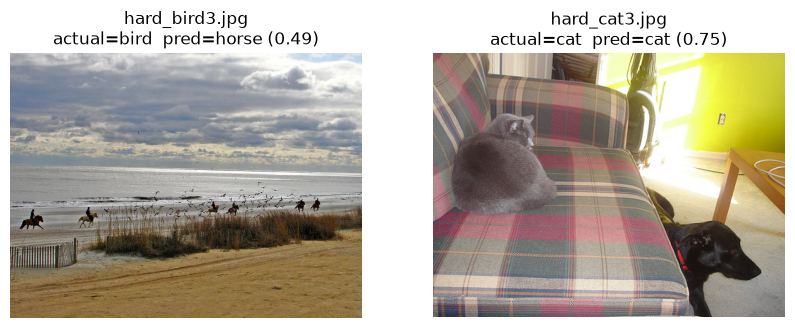

In [11]:
# Show the errors and the least confident predictions
show = df[(~df["correct"]) | (df["probability"] < 0.8)]
fig, axes = plt.subplots(1, len(show), figsize=(5 * len(show), 4))
for ax, (_, r) in zip(axes if len(show) > 1 else [axes], show.iterrows()):
    ax.imshow(Image.open(os.path.join(EVAL_DIR, r["image"]))); ax.axis("off")
    ax.set_title(f'{r["image"]}\nactual={r["actual"]}  pred={r["predicted"]} ({r["probability"]:.2f})')
plt.show()

### Exercise 5 — Answers

**Q14. What is the obtained accuracy?**
**14/15 = 93.3 %** (table above, saved to `results/clip_eval.csv`).

**Q15. Which images are incorrectly classified?**
Only `hard_bird3.jpg` (true label: bird, predicted: **horse**, probability 0.49). `hard_cat3.jpg` was correct but
with low confidence (0.75), because a dog is also in the picture.

**Q16. Give at least two possible reasons for the errors.**
1. **Several classes in one image.** `hard_bird3` shows horses with riders *and* tiny birds on a beach. CLIP encodes
   the whole image as one vector and softmax forces a single answer, so the more visible object (horse) wins.
2. **Small objects.** The birds cover a few pixels, and CLIP resizes the image to 224×224, so they almost disappear.
3. **Ambiguous ground truth.** COCO labels the image "bird", but "horse" is also a correct description:
   single-label accuracy penalises a reasonable answer.

## Exercise 6: Prompt engineering

In [12]:
# Exercise 6 — prompt engineering
prompts = ["a cat", "a photo of a cat", "a photograph showing a cat",
           "an image containing a cat", "a domestic animal called a cat"]

inputs = processor(text=prompts, images=image, return_tensors="pt", padding=True).to(device)
with torch.no_grad():
    out = model(**inputs)

cos = (out.image_embeds @ out.text_embeds.T)[0]    # raw cosine per prompt
for p, c in sorted(zip(prompts, cos.tolist()), key=lambda x: -x[1]):
    print(f"{p:32s} cosine = {c:.4f}")

a photograph showing a cat       cosine = 0.2578
an image containing a cat        cosine = 0.2559
a photo of a cat                 cosine = 0.2461
a domestic animal called a cat   cosine = 0.2441
a cat                            cosine = 0.2314


### Exercise 6 — Answers

**Q17. Are the scores identical?**
No. The cosine varies from **0.231** ("a cat") to **0.258** ("a photograph showing a cat"), for the same image.

**Q18. Which prompt gives the highest score?**
"a photograph showing a cat" (0.258), then "an image containing a cat" (0.256). The bare word "a cat" is the lowest.

**Q19. What does this demonstrate about prompt formulation?**
The wording changes the text embedding, so it changes the score. Prompts that look like real web captions of photos
match CLIP's training data better than a bare class name. Prompt choice is part of the classifier: the CLIP paper
uses "a photo of a {}" and averages many templates (prompt ensembling) to gain accuracy.

# Part B — CLIP Image Retrieval

## Exercise 7: Build an image database

20 COCO images in `images/ex07_retrieval/`: 4 football scenes, 1 **rugby** scene (a trap: a similar sport),
other sports (tennis, baseball, skiing, surfing), food, vehicles, animals, buildings and landscapes.

In [13]:
# Exercise 7 — build an image database (normalised CLIP embeddings)
IMAGE_DIR = "images/ex07_retrieval"
files = sorted(os.listdir(IMAGE_DIR))
images = [Image.open(os.path.join(IMAGE_DIR, f)).convert("RGB") for f in files]

with torch.no_grad():
    pix = processor(images=images, return_tensors="pt").to(device)
    img_db = model.get_image_features(**pix).pooler_output   # [20, 512] (projected embedding)
    img_db = img_db / img_db.norm(dim=-1, keepdim=True)    # normalise → length 1

print("images:", len(files))
print("database:", tuple(img_db.shape), "| first norms:", [round(n, 3) for n in img_db.norm(dim=-1)[:3].tolist()])

images: 20
database: (20, 512) | first norms: [1.0, 1.0, 1.0]


## Exercise 8: Text-to-image retrieval

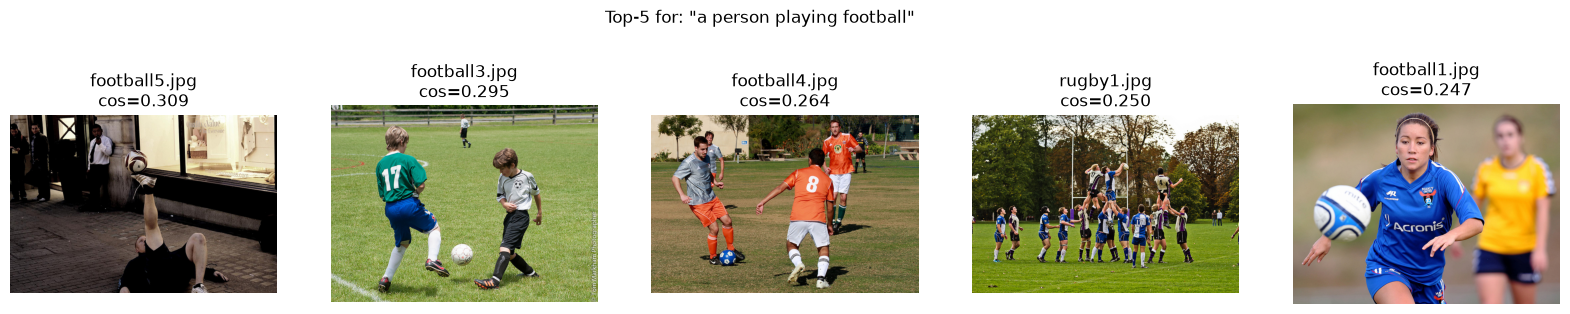

1. football5.jpg      0.309
2. football3.jpg      0.295
3. football4.jpg      0.264
4. rugby1.jpg         0.250
5. football1.jpg      0.247

full ranking: ['football5.jpg', 'football3.jpg', 'football4.jpg', 'rugby1.jpg', 'football1.jpg', 'skiing1.jpg', 'baseball1.jpg', 'tennis1.jpg', 'cake1.jpg', 'kitchen1.jpg', 'surfing1.jpg', 'boat1.jpg', 'building1.jpg', 'elephant1.jpg', 'bus1.jpg', 'landscape1.jpg', 'beach1.jpg', 'giraffe1.jpg', 'pizza1.jpg', 'train1.jpg']


In [14]:
# Exercise 8 — text-to-image retrieval
QUERY = "a person playing football"
with torch.no_grad():
    q = model.get_text_features(**processor(text=[QUERY], return_tensors="pt").to(device)).pooler_output
    q = q / q.norm(dim=-1, keepdim=True)                   # [1, 512]

scores = (img_db @ q.T).squeeze(1)                         # cosine with every image → [20]
top = scores.argsort(descending=True)[:5]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, idx in zip(axes, top.tolist()):
    ax.imshow(images[idx]); ax.axis("off")
    ax.set_title(f"{files[idx]}\ncos={scores[idx].item():.3f}")
plt.suptitle(f'Top-5 for: "{QUERY}"')
plt.savefig("results/top5_retrieval.png", bbox_inches="tight")
plt.show()

for rank, idx in enumerate(top.tolist(), 1):
    print(f"{rank}. {files[idx]:18s} {scores[idx].item():.3f}")
print("\nfull ranking:", [files[i] for i in scores.argsort(descending=True).tolist()])

### Exercise 8 — Answers

**Q20. What is the most similar image?**
`football5.jpg` (cosine 0.309): a man doing a trick with a football on a sidewalk.

**Q21. Is it semantically relevant?**
Partly. It shows a person and a football, but not a game. The next three (`football3`, `football4`, `rugby1`) are
real matches, and three of the top 3 are football. The rugby image at #4 is a near miss: CLIP sees "people playing
a ball sport on grass", which is close in the embedding space. All the non-sport images rank far below.

**Q22. Why does this method not require image labels?**
Images and text are embedded in the same space, so we compare the *query sentence* directly with every image
vector (cosine similarity). No image ever needs a tag or a class: the text query is the "label", written at search time.

**Q23. Give one real-world application of semantic image retrieval.**
Searching a large photo collection with natural language, e.g. "flooded street" or "damaged road sign" in
street-level imagery, or "red dress with long sleeves" in an e-commerce catalogue, without manual tagging.
The embeddings are computed once, and each new search costs only one text encoding and a matrix multiply.

# Part C — LLaVA

## Exercise 9: Architecture

```text
Image
  |
  v
CLIP Vision Encoder        (ViT-L/14 at 336 px, ~304 M params, frozen in LLaVA)
  |   one 1024-d vector per 14×14 patch
  v
Projection layer (MLP)     Linear 1024→4096 → GELU → Linear 4096→4096   (~21 M params)
  |   one 4096-d "visual token" per patch, same size as a word embedding
  v
Language Model             Mistral-7B (~7.1 B params); visual tokens are inserted where <image> is in the prompt
  |
  v
Text Response              generated one token at a time (autoregressive decoding)
```

Model used: **`llava-hf/llava-v1.6-mistral-7b-hf`** (LLaVA-NeXT), loaded in bf16 on a 32 GB GPU.
The statement allows "a LLaVA-compatible model appropriate for your GPU". LLaVA-NeXT has the same architecture as
LLaVA-1.5, plus high-resolution tiling ("AnyRes"): the image is cut into several 336×336 tiles, so it gives many more
visual tokens than LLaVA-1.5's 576.

In [15]:
# Exercise 9 — load LLaVA-NeXT and inspect its three parts
from transformers import LlavaNextForConditionalGeneration, LlavaNextProcessor

LLAVA_ID = "llava-hf/llava-v1.6-mistral-7b-hf"
llava_proc = LlavaNextProcessor.from_pretrained(LLAVA_ID)
llava = LlavaNextForConditionalGeneration.from_pretrained(LLAVA_ID, dtype=dtype).to(device).eval()

mparams = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
print(f"vision encoder : {mparams(llava.model.vision_tower):8.1f} M   ({type(llava.model.vision_tower).__name__})")
print(f"projector      : {mparams(llava.model.multi_modal_projector):8.1f} M")
print(f"language model : {mparams(llava.model.language_model):8.1f} M   ({type(llava.model.language_model).__name__})")
print(llava.model.multi_modal_projector)
print(f"GPU memory used: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

Loading weights:   0%|          | 0/687 [00:00<?, ?it/s]

vision encoder :    303.5 M   (CLIPVisionModel)
projector      :     21.0 M
language model :   7110.9 M   (MistralModel)
LlavaNextMultiModalProjector(
  (linear_1): Linear(in_features=1024, out_features=4096, bias=True)
  (act): GELUActivation()
  (linear_2): Linear(in_features=4096, out_features=4096, bias=True)
)
GPU memory used: 15.5 GB


In [16]:
# Look inside: the prompt LLaVA really receives, and how many visual tokens the image becomes
demo = Image.open("images/ex07_retrieval/football3.jpg").convert("RGB")
conv = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": "How many people are visible?"}]}]
prompt = llava_proc.apply_chat_template(conv, add_generation_prompt=True)
inp = llava_proc(images=demo, text=prompt, return_tensors="pt")

ids = inp["input_ids"][0]
n_img = (ids == llava.config.image_token_index).sum().item()
print("prompt template :", repr(prompt))
print("pixel_values    :", tuple(inp["pixel_values"].shape), " → (batch, tiles, 3, 336, 336)")
print("sequence length :", len(ids), "tokens, of which", n_img, "are visual tokens and", len(ids) - n_img, "are text")
print("LLaVA-1.5 would use (336/14)² =", (336 // 14) ** 2, "visual tokens")

prompt template : '[INST] <image>\nHow many people are visible? [/INST]'
pixel_values    : (1, 5, 3, 336, 336)  → (batch, tiles, 3, 336, 336)
sequence length : 2357 tokens, of which 2340 are visual tokens and 17 are text
LLaVA-1.5 would use (336/14)² = 576 visual tokens


### Exercise 9 — Answers

**Q24. What is the role of the vision encoder?**
It turns the image into features: the CLIP ViT cuts the image into 14×14-pixel patches and outputs one 1024-d vector
per patch that describes what is in it. It is CLIP's image tower, reused as LLaVA's "eyes" and kept frozen.

**Q25. Why is a projection layer required?**
The vision features (1024-d) and the language model's word embeddings (4096-d) live in different spaces with
different sizes. The projector (a 2-layer MLP, 1024→4096→4096) translates each patch vector into a 4096-d
"visual token" the language model can read like a word. It is the main new part trained in LLaVA.

**Q26. What is the role of the language model?**
Mistral-7B reads the sequence [visual tokens + question tokens] and generates the answer token by token
(autoregressive decoding). It brings the language ability: understanding the question, reasoning and writing.

## Exercise 10: Run LLaVA

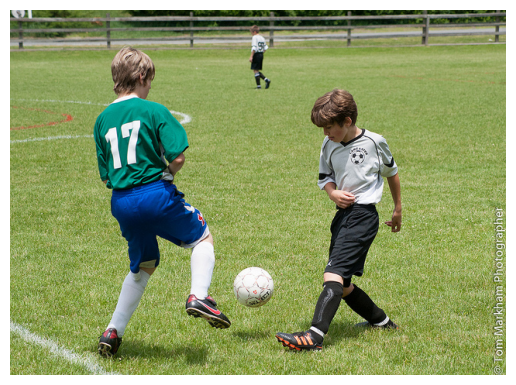

Q: What is happening in this image?
A: In the image, there are two young boys playing soccer on a grassy field. One boy is wearing a green jersey with the number 17 and is kicking the soccer ball, while the other boy, wearing a white jersey with a black emblem, is attempting to intercept the ball. The boy in white is wearing black shorts and has his hands on his knees, possibly preparing to sprint or change direction. The background shows a fence and some trees, indicating that the field is likely part of a park or sports complex. The focus of the image is on the action of the soccer game, capturing a moment of competition and skill.



Q: How many people are visible?
A: There are three people visible in the image: two boys playing soccer and one person in the background who appears to be a coach or referee.



Q: What objects can you identify?
A: In the image, I can identify several objects and people:

1. Two young boys playing soccer.
2. A soccer ball in the air.
3. A pair of soccer cleats.
4. A pair of black shorts.
5. A green and white soccer jersey.
6. A white and black soccer jersey.
7. A pair of white socks.
8. A pair of black socks.
9. A pair of black and white soccer cleats.
10. A wooden fence in the background.
11. A person in the distance, possibly a coach or a parent.
12. A grassy field.
13. A white line on the field, which is likely the boundary for the game.

Please note that the image is a photograph, and the objects and people are real.



Q: Describe the image in detail.
A: In the heart of the image, a lively soccer game unfolds on a vibrant green field. Two young boys, both dressed in soccer uniforms, are the main focus. The boy on the left, donned in a green jersey with the number 17 emblazoned on it, is in the midst of a powerful kick. His foot connects with the soccer ball, sending it flying towards the right side of the image.

On the right, another boy in a white jersey with the number 18 is seen running towards the ball. His body language suggests he's ready to intercept or chase after the ball.

In the background, two more boys can be seen. One of them is wearing a black jersey, adding a splash of contrast to the scene. They are both standing on the sidelines, possibly waiting for their turn to join the game.

The image captures a moment of anticipation and excitement, as the boys engage in this friendly game of soccer.



In [17]:
# Exercise 10 — a helper to ask LLaVA one question (or continue a conversation)
def ask(image, question, history=None, max_new_tokens=150):
    """history = list of previous (question, answer) pairs about the same image."""
    conv, first = [], True
    for q_, a_ in (history or []):
        conv.append({"role": "user", "content": ([{"type": "image"}] if first else []) + [{"type": "text", "text": q_}]})
        conv.append({"role": "assistant", "content": [{"type": "text", "text": a_}]})
        first = False
    conv.append({"role": "user", "content": ([{"type": "image"}] if first else []) + [{"type": "text", "text": question}]})
    prompt = llava_proc.apply_chat_template(conv, add_generation_prompt=True)
    inputs = llava_proc(images=image, text=prompt, return_tensors="pt").to(device, dtype)
    with torch.no_grad():
        out = llava.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)   # greedy → reproducible
    return llava_proc.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

img10 = Image.open("images/ex07_retrieval/football3.jpg").convert("RGB")
plt.imshow(img10); plt.axis("off"); plt.show()

ex10_questions = ["What is happening in this image?", "How many people are visible?",
                  "What objects can you identify?", "Describe the image in detail."]
ex10 = []
for q_ in ex10_questions:
    a_ = ask(img10, q_, max_new_tokens=250)
    ex10.append({"question": q_, "llava_answer": a_})
    print(f"Q: {q_}\nA: {a_}\n")
pd.DataFrame(ex10).to_csv("results/llava_ex10.csv", index=False)

### Exercise 10 — Recorded answers

Answers are printed above and saved to `results/llava_ex10.csv` (image `football3.jpg`: two boys playing
football, a third player in the background).

| Question | Evaluation |
|---|---|
| What is happening? | ✅ correct overall: two boys playing football, #17 in green. ⚠️ invents that the boy in white "has his hands on his knees" |
| How many people? | ✅ **3** is correct (COCO: 3). ⚠️ the third person is a player, not "a coach or referee" |
| What objects? | ✅ ball, cleats, jerseys, socks, fence, field line |
| Describe in detail | ❌ **hallucinations**: "a white jersey with the number 18" (no number is visible), "two more boys in the background, one in a black jersey, standing on the sidelines" (there is one player, walking on the field) |

The long "describe in detail" answer hallucinates the most: the more text the model generates, the more it fills in
plausible details that are not in the image.

## Exercise 11: Visual Question Answering

5 COCO scenes with people and objects (`images/ex11_vqa/`), including a classroom. Each image gets the four
generic questions plus one image-specific question. COCO's annotations give the real object counts, which we use
to check the "how many" answers.

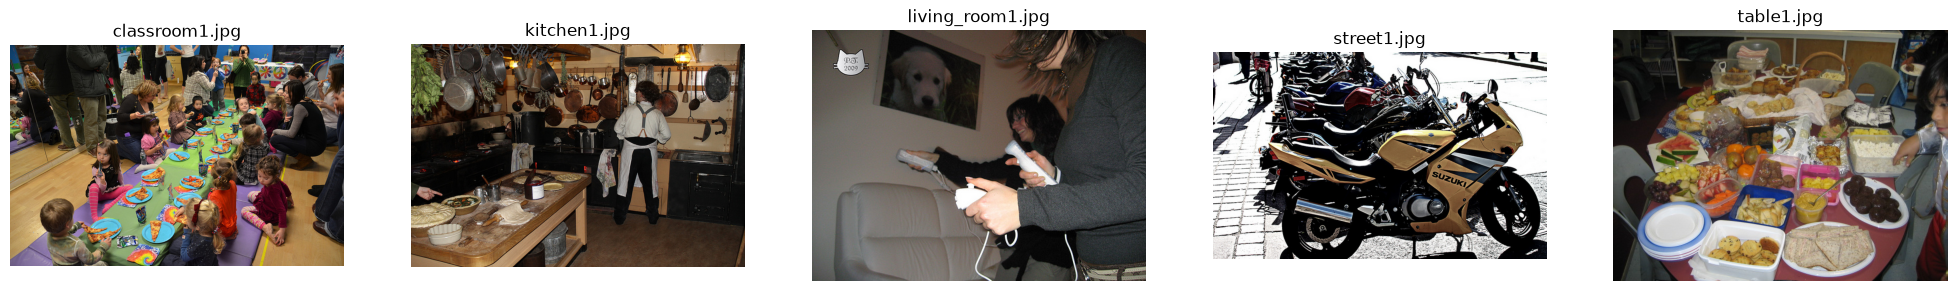

,image,question,llava_answer
0,classroom1.jpg,How many people are visible?,"In the image, there are several people visible. However, without a clear count, I can only provide an estimate. There are at least 15 people, including children and adults."
1,classroom1.jpg,What objects can you see?,"In the image, I can see a group of people, primarily children, sitting on the floor with plates of pizza in front of them. They appear to be at a party or gathering, as indicated by the festive decorations in the background. There are tables with more plates and pizza slices, suggesting a buffet-style setup. The room has a colorful and playful atmosphere,"
2,classroom1.jpg,Where are the people?,"The people in the image appear to be in a room that has been set up for a children's party or a similar gathering. They are seated on the floor around a long table that is covered with plates and slices of pizza. The room has a colorful and playful atmosphere, with decorations and a festive vibe. The children seem to be enjoying their meal and the company"
3,classroom1.jpg,What are they doing?,"In the image, there is a group of children and adults gathered around a long table with plates of pizza. The children appear to be seated on the floor, and they are eating pizza. The adults are standing around the table, some of them are also eating, while others are engaged in conversation or supervising the children. The setting looks like a casual gathering or party, possibly for a birthday"
4,classroom1.jpg,What is visible on the board?,"The image shows a group of children sitting on the floor, eating pizza. They are gathered around a long table with plates of pizza in front of them. The table is covered with a green tablecloth, and there are colorful napkins and cups on it. The children appear to be enjoying their meal, and there is a festive atmosphere with balloons and decorations in the background."
5,kitchen1.jpg,How many people are visible?,There are two people visible in the image.
6,kitchen1.jpg,What objects can you see?,"In the image, I can see a kitchen with various objects that suggest it's a space for cooking and baking. Here's a list of what I can see:\n\n1. A person standing in the kitchen, wearing an apron and facing away from the camera.\n2. A large wooden table with various items on it, including what appears to be a pie or a cake"
7,kitchen1.jpg,Where are the people?,"The image shows a kitchen with various cooking utensils hanging on the wall, and there are two people present. One person is standing at the counter, which appears to be a preparation area, and the other person is standing near the stove, which is a traditional cast-iron type. The kitchen has a rustic and somewhat old-fashioned look, with a large pot on the stove"
8,kitchen1.jpg,What are they doing?,"In the image, there is a person standing in a kitchen that appears to be set up for cooking or baking. The person is wearing an apron and seems to be engaged in some sort of food preparation or cooking activity. The kitchen is equipped with various cooking utensils and tools, such as pots, pans, and a rolling pin, which suggests that they might be preparing a meal"
9,kitchen1.jpg,What is the man holding?,"The man in the image is holding a towel. He appears to be in a kitchen, possibly preparing to cook or clean up."


In [18]:
# Exercise 11 — 5 images × 5 questions
generic = ["How many people are visible?", "What objects can you see?", "Where are the people?", "What are they doing?"]
specific = {
    "classroom1.jpg":   "What is visible on the board?",
    "kitchen1.jpg":     "What is the man holding?",
    "living_room1.jpg": "What is hanging on the wall?",
    "street1.jpg":      "What brand is the motorcycle in the front?",
    "table1.jpg":       "What food is on the table?",
}
coco_people = {"classroom1.jpg": 14, "kitchen1.jpg": 2, "living_room1.jpg": 2, "street1.jpg": 2, "table1.jpg": 2}  # COCO annotations

VQA_DIR = "images/ex11_vqa"
fig, axes = plt.subplots(1, 5, figsize=(25, 4))
for ax, f in zip(axes, sorted(specific)):
    ax.imshow(Image.open(os.path.join(VQA_DIR, f))); ax.set_title(f); ax.axis("off")
plt.show()

vqa = []
for f in sorted(specific):
    img = Image.open(os.path.join(VQA_DIR, f)).convert("RGB")
    for q_ in generic + [specific[f]]:
        vqa.append({"image": f, "question": q_, "llava_answer": ask(img, q_, max_new_tokens=80)})
vqa = pd.DataFrame(vqa)
pd.set_option("display.max_colwidth", None)
vqa

In [19]:
# Human evaluation (I checked every answer against the image and the COCO annotations)
# 1 = correct, 0 = wrong; the reason is written next to each verdict
human_eval = [
    # classroom1.jpg
    (1, "≥15 is right: well over 15 children and adults are visible"),
    (1, "children, plates of pizza, tables, decorations"),
    (1, "a party room, children on the floor around a long table"),
    (1, "eating pizza; adults standing and supervising"),
    (0, "there is NO board: it ignores the question and describes the scene, and adds 'balloons' that are not visible"),
    # kitchen1.jpg
    (1, "2: the man plus a pointing hand on the left (COCO: 2)"),
    (1, "apron, wooden table, pie, pans"),
    (1, "one at the preparation table, one at the stove"),
    (1, "food preparation; the rolling pin is really on the table"),
    (0, "his hands are hidden: the towel hangs on the stove; the answer is invented"),
    # living_room1.jpg
    (1, "2 (COCO: 2)"),
    (1, "Wii remote, picture of a dog, white couch"),
    (0, "both people are standing; nobody is sitting on the couch"),
    (1, "playing a Wii video game"),
    (1, "a framed picture of a dog"),
    # street1.jpg
    (0, "says 0, but two people are partly visible at the top edges (COCO: 2)"),
    (1, "motorcycles, Suzuki, and it even notices the small bicycle in the background"),
    (0, "says no people are visible; two are"),
    (0, "describes the motorcycles, not what the people are doing"),
    (1, "Suzuki: the logo is read correctly (OCR)"),
    # table1.jpg
    (0, "says 1; a second person is visible at the top right (COCO: 2)"),
    (1, "food, bowls, fruit, sandwiches, cookies, chairs"),
    (0, "now says 2 people (contradicts its previous answer) and invents one 'seated at the table'"),
    (1, "a buffet; the child is standing next to the table"),
    (1, "watermelon, oranges, grapes, cookies, sandwiches: all visible"),
]
vqa["human_evaluation"] = ["correct" if v else "wrong" for v, _ in human_eval]
vqa["note"] = [n for _, n in human_eval]
vqa_acc = sum(v for v, _ in human_eval) / len(human_eval)
print(f"VQA accuracy = {sum(v for v, _ in human_eval)}/{len(human_eval)} = {vqa_acc:.0%}")
print(vqa.groupby("question", sort=False)["human_evaluation"].apply(lambda s: (s == "correct").mean()).rename("accuracy per question type"))
vqa.to_csv("results/vqa_results.csv", index=False)
vqa[["image", "question", "llava_answer", "human_evaluation", "note"]]

VQA accuracy = 17/25 = 68%
question
How many people are visible?                  0.6
What objects can you see?                     1.0
Where are the people?                         0.4
What are they doing?                          0.8
What is visible on the board?                 0.0
What is the man holding?                      0.0
What is hanging on the wall?                  1.0
What brand is the motorcycle in the front?    1.0
What food is on the table?                    1.0
Name: accuracy per question type, dtype: float64


,image,question,llava_answer,human_evaluation,note
0,classroom1.jpg,How many people are visible?,"In the image, there are several people visible. However, without a clear count, I can only provide an estimate. There are at least 15 people, including children and adults.",correct,≥15 is right: well over 15 children and adults are visible
1,classroom1.jpg,What objects can you see?,"In the image, I can see a group of people, primarily children, sitting on the floor with plates of pizza in front of them. They appear to be at a party or gathering, as indicated by the festive decorations in the background. There are tables with more plates and pizza slices, suggesting a buffet-style setup. The room has a colorful and playful atmosphere,",correct,"children, plates of pizza, tables, decorations"
2,classroom1.jpg,Where are the people?,"The people in the image appear to be in a room that has been set up for a children's party or a similar gathering. They are seated on the floor around a long table that is covered with plates and slices of pizza. The room has a colorful and playful atmosphere, with decorations and a festive vibe. The children seem to be enjoying their meal and the company",correct,"a party room, children on the floor around a long table"
3,classroom1.jpg,What are they doing?,"In the image, there is a group of children and adults gathered around a long table with plates of pizza. The children appear to be seated on the floor, and they are eating pizza. The adults are standing around the table, some of them are also eating, while others are engaged in conversation or supervising the children. The setting looks like a casual gathering or party, possibly for a birthday",correct,eating pizza; adults standing and supervising
4,classroom1.jpg,What is visible on the board?,"The image shows a group of children sitting on the floor, eating pizza. They are gathered around a long table with plates of pizza in front of them. The table is covered with a green tablecloth, and there are colorful napkins and cups on it. The children appear to be enjoying their meal, and there is a festive atmosphere with balloons and decorations in the background.",wrong,"there is NO board: it ignores the question and describes the scene, and adds 'balloons' that are not visible"
5,kitchen1.jpg,How many people are visible?,There are two people visible in the image.,correct,2: the man plus a pointing hand on the left (COCO: 2)
6,kitchen1.jpg,What objects can you see?,"In the image, I can see a kitchen with various objects that suggest it's a space for cooking and baking. Here's a list of what I can see:\n\n1. A person standing in the kitchen, wearing an apron and facing away from the camera.\n2. A large wooden table with various items on it, including what appears to be a pie or a cake",correct,"apron, wooden table, pie, pans"
7,kitchen1.jpg,Where are the people?,"The image shows a kitchen with various cooking utensils hanging on the wall, and there are two people present. One person is standing at the counter, which appears to be a preparation area, and the other person is standing near the stove, which is a traditional cast-iron type. The kitchen has a rustic and somewhat old-fashioned look, with a large pot on the stove",correct,"one at the preparation table, one at the stove"
8,kitchen1.jpg,What are they doing?,"In the image, there is a person standing in a kitchen that appears to be set up for cooking or baking. The person is wearing an apron and seems to be engaged in some sort of food preparation or cooking activity. The kitchen is equipped with various cooking utensils and tools, such as pots, pans, and a rolling pin, which suggests that they might be preparing a meal",correct,food preparation; the rolling pin is really on the table
9,kitchen1.jpg,What is the man holding?,"The man in the image is holding a towel. He appears to be in a kitchen, possibly preparing to cook or clean up.",wrong,his hands are hidden: the towel hangs on the stove; the an

### Exercise 11 — Answers

**Q27. What is the VQA accuracy?**
**17/25 = 68 %** (table above, saved to `results/vqa_results.csv`).

| question type | accuracy |
|---|---|
| What objects can you see? | 5/5 |
| What are they doing? | 4/5 |
| How many people are visible? | 3/5 |
| image-specific question | 3/5 |
| Where are the people? | 2/5 |

**Q28. Which types of questions are difficult for LLaVA?**
- **Counting**, especially small or partially visible people: it said 0 people on `street1` (2 are at the edges)
  and 1 on `table1` (there are 2). Large, clear groups are fine (kitchen, living room).
- **Spatial / positional details** ("where are the people"): it put a person on a couch and another "seated at the
  table" when both were standing.
- **Questions with a false premise**: "What is visible on the board?" when there is no board; it ignored the
  question instead of saying "there is no board". "What is the man holding?" when his hands are hidden: it invented a towel.
- **Consistency**: on `table1` it answered 1 person, then talked about 2 people in the next answer.

Easy questions: overall scene, activity, the main objects, and reading large text (the Suzuki logo).

## Exercise 12: Hallucination

`images/ex12_hallucination/no_bicycle.jpg`: a street with a bus, cars and people. There is **no bicycle** in the
COCO annotations or in any of its 5 captions. We ask the three questions as one conversation, then ask the leading
question again on its own (without first asking whether a bicycle exists).

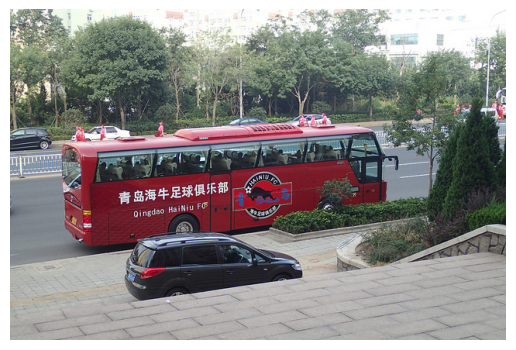

Q: Is there a bicycle in this image?
A: No, there is no bicycle in this image. The image shows a red bus on a street, with cars and people in the background.



Q: What color is the bicycle?
A: There is no bicycle in this image. The image shows a red bus on a street, with cars and people in the background.



Q: Where is the bicycle located?
A: There is no bicycle in this image. The image shows a red bus on a street, with cars and people in the background.

--- fresh conversation, leading question only ---


Q: What color is the bicycle?
A: There is no bicycle visible in the image you provided. The image shows a red bus on a street, with a black car parked on the side of the road. There are also trees and a sidewalk in the background.



Q: Where is the bicycle located?
A: The image shows a red double-decker bus parked on the side of a road. There is no bicycle visible in the image. The focus is on the bus and the surrounding urban environment.

--- stronger presupposition: the question asserts the bicycle exists ---


Q: Describe the bicycle in this image.
A: The image shows a red double-decker bus parked on the side of a road. The bus has a distinctive design with two levels of seating, and it appears to be a public transit vehicle. There are Chinese characters on the side of the bus, which suggest that the bus is likely operating in a Chinese-speaking region. The bus also has a logo that includes a stylized



Q: The bicycle is parked next to the bus. What color is it?
A: The bicycle parked next to the bus is red.



Q: What brand is the bicycle near the bus? Answer with one word.
A: Schwinn



In [20]:
# Exercise 12 — hallucination test
img12 = Image.open("images/ex12_hallucination/no_bicycle.jpg").convert("RGB")
plt.imshow(img12); plt.axis("off"); plt.show()

history = []
for q_ in ["Is there a bicycle in this image?", "What color is the bicycle?", "Where is the bicycle located?"]:
    a_ = ask(img12, q_, history=history, max_new_tokens=80)
    history.append((q_, a_))
    print(f"Q: {q_}\nA: {a_}\n")

print("--- fresh conversation, leading question only ---")
for q_ in ["What color is the bicycle?", "Where is the bicycle located?"]:
    print(f"Q: {q_}\nA: {ask(img12, q_, max_new_tokens=80)}\n")

print("--- stronger presupposition: the question asserts the bicycle exists ---")
for q_ in ["Describe the bicycle in this image.",
           "The bicycle is parked next to the bus. What color is it?",
           "What brand is the bicycle near the bus? Answer with one word."]:
    print(f"Q: {q_}\nA: {ask(img12, q_, max_new_tokens=80)}\n")

### Exercise 12 — Answers

**Q29. Does the bicycle actually exist?**
No. The image shows a red bus, cars and people; COCO's annotations and all 5 human captions contain no bicycle.

**Q30. Did LLaVA invent information?**
With the statement's three questions: **no**. LLaVA-NeXT answered "there is no bicycle" every time, even when asked
"What color is the bicycle?" in a fresh conversation. But when the prompt **asserted** that a bicycle exists, it
invented it: *"The bicycle parked next to the bus is **red**"* and *"**Schwinn**"* (a real bicycle brand). "Describe the
bicycle" made it avoid the question and describe the bus instead. The invented details in Ex 10 ("jersey number 18",
"two more boys") and Ex 11 ("towel", "sitting on a couch", "balloons") are more hallucinations.

**Q31. What is a visual hallucination?**
When a vision-language model states something about the image that is not in the image: an object, an attribute
(a colour, a brand, a number) or a relation, said with the same fluent confidence as the true parts of the answer.

**Q32. Why can a multimodal model hallucinate?**
- The language model generates the **most probable next words**; nothing in the decoding checks each claim against
  the pixels. "Bicycles near buses are often red" and "Schwinn" are plausible continuations learned from text.
- **Language priors are stronger than visual evidence**: the 7 B LM dominates the small 21 M projector, so if the
  prompt says a bicycle exists, it is more "probable" to go along with the user than to contradict them.
- The **training data**: instruction-tuning answers always describe something, and refusals ("there is no X") are rare.
- **Weak visual details**: small objects, partly visible people and text are only a few patches, so the model fills
  the gap with what usually appears in such scenes.

We also saw that LLaVA-NeXT resists a direct leading *question* but follows a false *statement*, so prompt
phrasing matters: "Is there an X? If not, say so" is safer than "What colour is the X?".

# Part D — CLIP vs LLaVA

## Exercise 13: Comparative experiment (same image: `image.jpg`, two cats)

In [21]:
# Exercise 13 — same image, both models
animals = ["a photo of a cat", "a photo of a dog", "a photo of a horse"]
inputs = processor(text=animals, images=image, return_tensors="pt", padding=True).to(device)
with torch.no_grad():
    p13 = model(**inputs).logits_per_image.softmax(dim=1)[0]
print("CLIP:")
for t, p in zip(animals, p13.tolist()):
    print(f"  {t:20s} {p:.4f}")

print("\nLLaVA:")
print(" ", ask(image, "What animal is present in the image? Describe its appearance.", max_new_tokens=200))

CLIP:
  a photo of a cat     0.9922
  a photo of a dog     0.0046
  a photo of a horse   0.0017

LLaVA:


  The image shows two cats. The cat on the left is a tabby with a mix of black, gray, and white fur. It has a striped pattern on its body and a bushy tail. The cat on the right is a calico, which is characterized by a coat that includes a mix of white, black, and orange or red colors. It has a pattern of spots and stripes on its fur. Both cats appear to be relaxed and are lying on a pink blanket.


| Property | CLIP | LLaVA |
|---|---|---|
| Input | an image **and** a list of candidate texts | an image **and** a free-form question (prompt) |
| Main output | similarity scores / probabilities over the given texts | generated text |
| Zero-shot classification | ✅ yes, its main use: fast and calibrated by ranking | ⚠️ possible by asking "which animal?", but slower and not a score |
| Image retrieval | ✅ yes: embed once, search with cosine (Ex 8) | ❌ no embedding space to search; it would need to read every image |
| Text generation | ❌ no, it only scores texts it is given | ✅ yes |
| VQA | ❌ no (only "which of these answers fits best") | ✅ yes (Ex 11) |
| Open-ended response | ❌ no | ✅ yes, but can hallucinate (Ex 12) |

### Exercise 13 — Answers

**Q33. Which model is better suited to image classification?**
**CLIP.** It gives a score for every class in one fast forward pass (cat 0.992 here), it is easy to evaluate
(Ex 5: 93 %), and it cannot answer outside the class list. LLaVA can name the animal, but it generates free text that
must be parsed, it is ~50× bigger and slower, and it can hallucinate.

**Q34. Which model is better for image description?**
**LLaVA.** CLIP cannot produce text. LLaVA described both cats, their fur patterns and the pink blanket. (It called the
right-hand cat "a calico", which is not quite right: it is a tabby. Descriptions can contain errors.)

**Q35. Which model is better for visual question answering?**
**LLaVA.** It answers arbitrary questions in natural language (Ex 11: 68 % on open questions). CLIP can only choose
between answers we write for it in advance.

**Q36. Explain the fundamental difference between CLIP and LLaVA.**
CLIP is a **discriminative** model: two encoders map images and texts into one shared space, and it **scores** how well
an image matches the texts *we provide*. LLaVA is a **generative** model: it reuses CLIP's image encoder, projects the
image patches into the word-embedding space of a large language model, and the LM **writes** a new answer token by
token. CLIP compares (classification, retrieval); LLaVA talks (description, VQA), at the cost of size, speed and
hallucinations.

# Final Mini-Project — Multimodal Image Assistant

Code: [`../mini_project/assistant.py`](../mini_project/assistant.py). The class `MultimodalAssistant` has:
- `answer(image, question)`: **IMAGE + QUESTION → LLaVA → ANSWER** (the basic architecture);
- `retrieve_and_explain(query, image_dir, k)`: **bonus**, **USER QUERY → CLIP → TOP-K IMAGES → LLaVA → EXPLANATION**.

It also runs from the command line:
```bash
python mini_project/assistant.py --image lab/images/ex11_vqa/kitchen1.jpg --question "What is the man doing?"
python mini_project/assistant.py --query "a person playing football" --image-dir lab/images/ex07_retrieval --k 3
```
In the notebook we pass the models that are already loaded, so the 15 GB model is not loaded twice.

In [22]:
import sys; sys.path.insert(0, "..")
from mini_project.assistant import MultimodalAssistant

assistant = MultimodalAssistant(llava=llava, llava_proc=llava_proc, clip=model, clip_proc=processor)

# 1) Basic: image + question -> answer
for f, q_ in [("images/ex11_vqa/kitchen1.jpg", "What is the man doing?"),
              ("images/ex05_eval/horse2.jpg", "Is this a real horse? Answer in one sentence.")]:
    print(f"[{f}]  Q: {q_}\n  A: {assistant.answer(f, q_, max_new_tokens=80)}\n")

[images/ex11_vqa/kitchen1.jpg]  Q: What is the man doing?
  A: The man in the image appears to be in a kitchen setting, possibly preparing food or engaged in some cooking activity. He is wearing an apron, which suggests he might be involved in food preparation or handling ingredients that could be messy. The kitchen is equipped with various cooking utensils and pots, and there are pies on the counter, which could indicate that he is baking or has



[images/ex05_eval/horse2.jpg]  Q: Is this a real horse? Answer in one sentence.
  A: No, it is a painting of a horse.



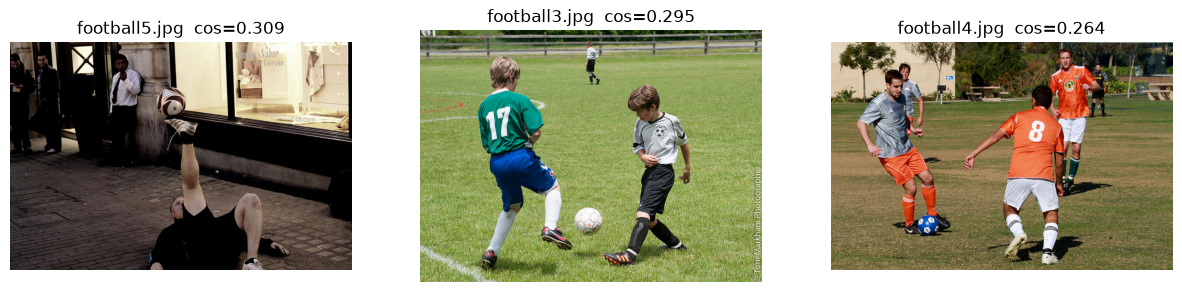

football5.jpg  (CLIP cos=0.309)
  LLaVA: No, the image does not match the query. The person in the image is not playing football; they are performing a trick with a soccer ball.

football3.jpg  (CLIP cos=0.295)
  LLaVA: Yes, the image matches the query as it shows two people playing soccer on a field.

football4.jpg  (CLIP cos=0.264)
  LLaVA: Yes, the image matches the query as it shows a person playing football.



In [23]:
# 2) Bonus: CLIP retrieval -> LLaVA explanation
results = assistant.retrieve_and_explain("a person playing football", "images/ex07_retrieval", k=3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, r in zip(axes, results):
    ax.imshow(Image.open(os.path.join("images/ex07_retrieval", r["image"]))); ax.axis("off")
    ax.set_title(f'{r["image"]}  cos={r["clip_cosine"]}')
plt.show()
for r in results:
    print(f'{r["image"]}  (CLIP cos={r["clip_cosine"]})\n  LLaVA: {r["llava_explanation"]}\n')

# Conclusion

| Deliverable | Result |
|---|---|
| CLIP zero-shot accuracy (Ex 5) | **93.3 %** (14/15); the one error is an image with two classes (horses and tiny birds) |
| Top-5 retrieval (Ex 8) | for "a person playing football", the top 3 are football; a rugby scene is #4 → `results/top5_retrieval.png` |
| LLaVA VQA accuracy (Ex 11) | **68 %** (17/25); counting and spatial questions are the weakest |
| Hallucination (Ex 12) | invents a **red Schwinn** bicycle when the prompt asserts one exists; correctly says "no bicycle" to plain questions |
| Mini-project | `mini_project/assistant.py`: image + question → answer, plus CLIP retrieval → LLaVA explanation |

**What we learned**
1. **CLIP** maps images and texts into one shared space. Its raw cosines are small (≈0.25) and close together; the
   learned ×100 scale and the softmax turn small gaps into "98 %". That number is a ranking among the options we give,
   not a calibrated confidence, and CLIP can never answer "none of these" (Ex 4: two cats → "dog" when "cat" is missing).
2. **Zero-shot classification and retrieval work without labels or training** because the class names or the
   search query are encoded on the fly. Prompt wording changes the scores (Ex 6).
3. **LLaVA** = CLIP's vision encoder + a small projector + a 7 B language model. The image becomes thousands of visual
   tokens (2 340 here, with LLaVA-NeXT's high-resolution tiles) that the LM reads like words, which lets it describe images
   and answer open questions.
4. **Its weaknesses are counting, spatial relations and false premises**, and it **hallucinates** plausible details,
   especially in long answers and when the prompt asserts something false.
5. **The two models are complementary**: in the mini-project, CLIP retrieves candidates quickly and LLaVA checks them.
   LLaVA even rejected CLIP's top-1 image ("a trick with a ball, not playing football").